# 🧪 LAB: Machine Learning to Predict Concrete Compressive Strength

In this lab, you will apply `PyTorch` to a real-world data problem. You will implement a Neural Network in `PyTorch` using the new functionalities introduced this week and compare its performance with a Support Vector Machine and Linear Regression.

Your goal is to predict the **compressive strength of concrete** (the outcome variable, *Y*) based on a set of input features (*X*), including:
**Cement, Blast Furnace Slag, Fly Ash, Water, Superplasticizer, Coarse Aggregate, Fine Aggregate, and Age.**

This dataset and problem are based on the following paper:

- I-Cheng Yeh, "Modeling of strength of high performance concrete using artificial neural networks," Cement and Concrete Research, Vol. 28, No. 12, pp. 1797-1808 (1998). [Link to the paper](yeh1998.pdf).


---

**Collaboration Note**: This assignment is designed to support collaborative work. We encourage you to divide tasks among group members so that everyone can contribute meaningfully. Many components of the assignment can be approached in parallel or split logically across team members. Good coordination and thoughtful integration of your work will lead to a stronger final result.

---

In total, this lab assignment will be worth **100 points**.

--- 
**Submission notes**:

* Write down all group members' names, or at least the group name (if you have one and you previously provided it), in the first cell of the notebook.

* Verify that the notebook runs as expected and that all required outputs are included.

NAME(s) = "Shreyans Jain, Luke Hakso, Thomas Gao"

## 0. Overall Instructions 

In this lab, you will work with three models: a **Neural Network**, a **Support Vector Machine (SVM)**, and some form of **Linear Regression**. Each should meet the following requirements:

- **Do not tune the models**. For example, for the Neural Network, choose any number of layers and hidden units you prefer; for the SVM, select a kernel of your choice (e.g., linear, RBF, polynomial), etc.

- **Evaluate model performance using k-fold cross-validation**. That is, run each model using a chosen number of folds (*k*), and report the average performance across all folds. You may select the value of *k* that you want.

- **Be careful with data preprocessing**. Apply all preprocessing steps properly to avoid data leakage (e.g. standardizing features before data splitting)

## 1. Pre-implementation Group Discussion (15 points)

In your group, discuss, agree on, and elaborate the following points:

- **Descriptive analysis**. Identify what exploratory or descriptive analyses you can perform to better understand the relationship between each input variable and the outcome. Consider both visual (e.g., scatter plots, histograms) and statistical summaries.

- **Data preprocessing**. Decide what preprocessing steps are necessary given that you will be using neural networks. 

- **Model configuration**. Specify which cost function and output layer activation are most appropriate for your problem type (e.g., regression vs. classification). Explain your reasoning based on the nature of the outcome variable.

- **Performance evaluation**. Describe how you will perform k-fold cross-validation to assess your model’s performance. Include how you will divide the data, compute metrics across folds, and report the final averaged results.

**1) Descriptive analysis.**

The checks come first, because those are the ones that will save us time later. Row count, missing values, duplicates, and describe() so the scales are visible. Coarse aggregate sits near 1000. Superplasticizer rarely passes 10. Age runs from a single day out to 365, which is already a hint about the shape of this problem. Histograms of all nine variables follow, and we expect slag, fly ash and superplasticizer to bunch at zero, since plenty of mixes just don’t use them. That zero is an absence, not a gap in the records, so imputing it would be wrong. Then we plot strength against each of the eight inputs, and age a second time on a log axis with the mean strength at each age. Plots, not a correlation table. A correlation of 0.2 fits a weak line as happily as a strong curve, and the number never tells us which. Duplicates we check for one narrow reason. If a mix appears twice and the copies get split across training and validation, the score flatters us, and we would rather write that down than hope nobody looks. We add no features either. Yeh builds water to cement ratios and does better for it, which is tempting, but the eight raw columns keep every model looking at the same data, so Section 5 compares models rather than feature sets.

**2) Data preprocessing.**

Inputs spread this far apart stretch the loss surface, and Adam tolerates that without repairing it. We standardize y as well, which keeps the MSE near 1 and the loss legible while training, and it pays off again for the SVM, where a default epsilon of 0.1 is a sensible tube in standard deviations and a nonsense one in MPa. Predictions come back to MPa before any metric is computed. An error of 6 MPa means something to a person. An error of 0.37 standard deviations does not. Both scalers are fit inside each fold, on training rows only. Fit them on everything and the mean quietly carries the validation rows, which is the kind of error nobody notices until the results look suspiciously good. Beyond that there is nothing to do, since the data are complete and entirely numeric. We leave age alone, even though the plots are practically begging for a log, because the interesting question is whether the network finds that curve without help.

**3) Model configuration.**

Strength is continuous and can keep climbing, so this is regression, and that settles both choices the question asks about. We use nn.MSELoss. The output is a single unit with no activation, nn.Identity. A sigmoid squashes the output and could never reach 80 MPa, and a ReLU could never return the negative values a standardized y takes for every below average mix. Hidden layers use nn.ReLU. The optimizer is Adam. The architecture is one hidden layer of 8 units, which is what Yeh used. Learning rate 0.01, batch size 32, 200 epochs. We guessed once and kept it, since the lab says not to tune. Fixed it once, then reused it in every fold. The other two models follow the same rule, so the SVM is an RBF kernel on library defaults and the linear model is least squares with no penalty.

**4) Performance evaluation.**


We used KFold with k = 5, shuffled, fixed seed, one splitter shared by all four models. That sharing is the part that matters. Give each model its own folds and a gap of 0.03 could be the model or merely the split, with no way to separate the two. Five folds leave about 206 mixes for validation, steady enough without paying for ten fits. Inside a fold we fit the scalers on the training rows, train from scratch, predict the held out fold, undo the scaling, and record R^2, RMSE and MAE on validation along with R^2 on training, which lets us point at overfitting with a number instead of a feeling. We never stop early on the validation fold, since choosing the stopping point from the data that grades us is tuning in a thinner disguise. Each mean then gets reported beside its standard deviation, mostly to keep us honest, because five numbers make it very easy to get excited about a difference smaller than the noise. One admission in advance. These scores are probably a bit optimistic, what with the duplicates helping us and mixes from a common source landing on both sides of a split. When Yeh holds out whole data sources, test R^2 slides from about 0.91 down to somewhere between 0.81 and 0.90, which is roughly what we are letting go.

## 2. Descriptive analysis (10 points)

Apply the descriptive analyses that your group agreed upon in the previous section.

**Load the dataset before beginning the descriptive analysis; you will also use it in the following sections.**

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv("data/cement.csv")

# the raw headers are long and have stray spaces, so shorten them
df.columns = ["cement", "slag", "fly_ash", "water", "superplasticizer", "coarse_agg", "fine_agg", "age", "strength"]
features = df.columns[:-1].tolist()

print(f"Rows: {len(df)}, columns: {df.shape[1]}")
print(f"Missing values: {df.isna().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
df.describe().T.round(2)

Rows: 1030, columns: 9
Missing values: 0
Duplicate rows: 25


,count,mean,std,min,25%,50%,75%,max
cement,1030.0,281.17,104.51,102.00,192.38,272.90,350.00,540.0
slag,1030.0,73.90,86.28,0.00,0.00,22.00,142.95,359.4
fly_ash,1030.0,54.19,64.00,0.00,0.00,0.00,118.30,200.1
water,1030.0,181.57,21.35,121.80,164.90,185.00,192.00,247.0
superplasticizer,1030.0,6.20,5.97,0.00,0.00,6.40,10.20,32.2
coarse_agg,1030.0,972.92,77.75,801.00,932.00,968.00,1029.40,1145.0
fine_agg,1030.0,773.58,80.18,594.00,730.95,779.50,824.00,992.6
age,1030.0,45.66,63.17,1.00,7.00,28.00,56.00,365.0
strength,1030.0,35.82,16.71,2.33,23.71,34.44,46.14,82.6


In [5]:
# share of rows where each input is exactly zero
(df[features] == 0).mean().round(2)

cement              0.00
slag                0.46
fly_ash             0.55
water               0.00
superplasticizer    0.37
coarse_agg          0.00
fine_agg            0.00
age                 0.00
dtype: float64

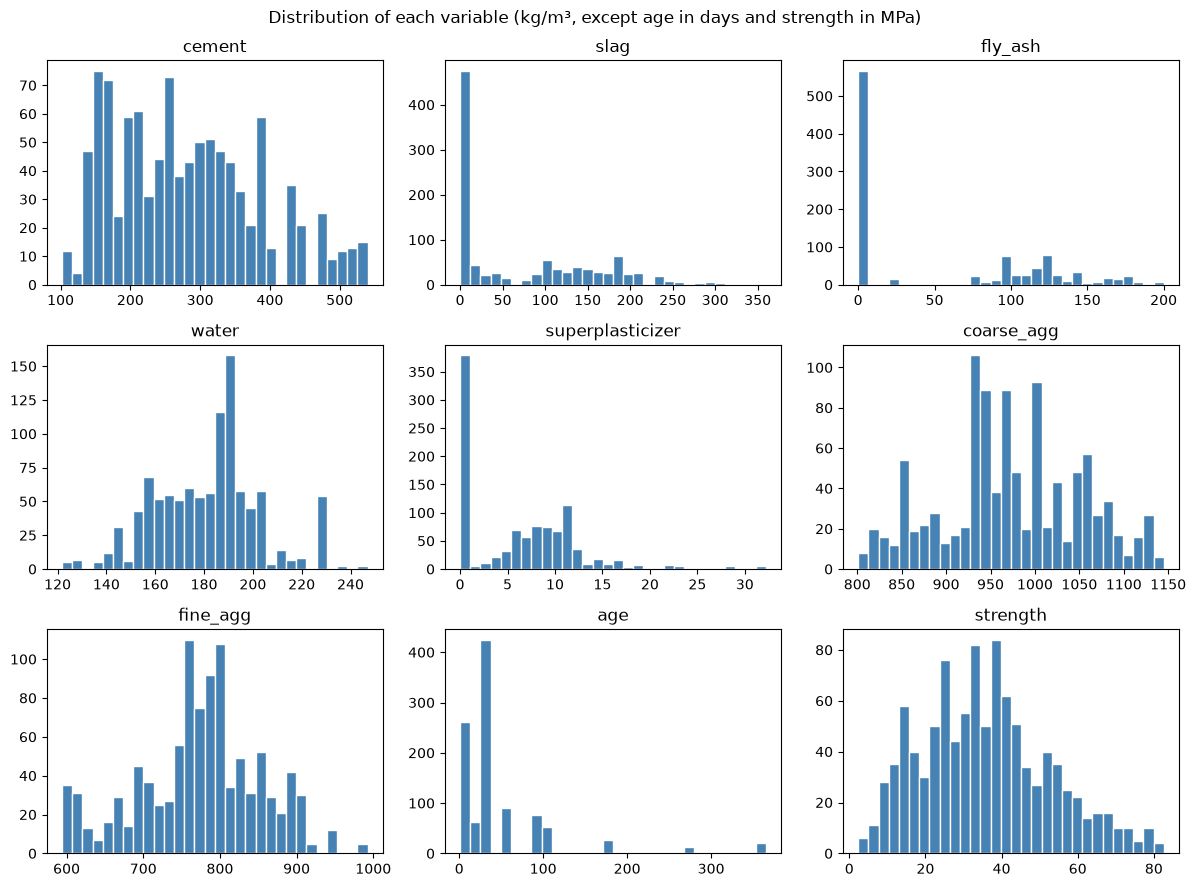

In [6]:
fig, axes = plt.subplots(3, 3, figsize=(12, 9))
for ax, col in zip(axes.ravel(), df.columns):
    ax.hist(df[col], bins=30, color="steelblue", edgecolor="white")
    ax.set_title(col)
fig.suptitle("Distribution of each variable (kg/m³, except age in days and strength in MPa)")
plt.tight_layout()
plt.show()

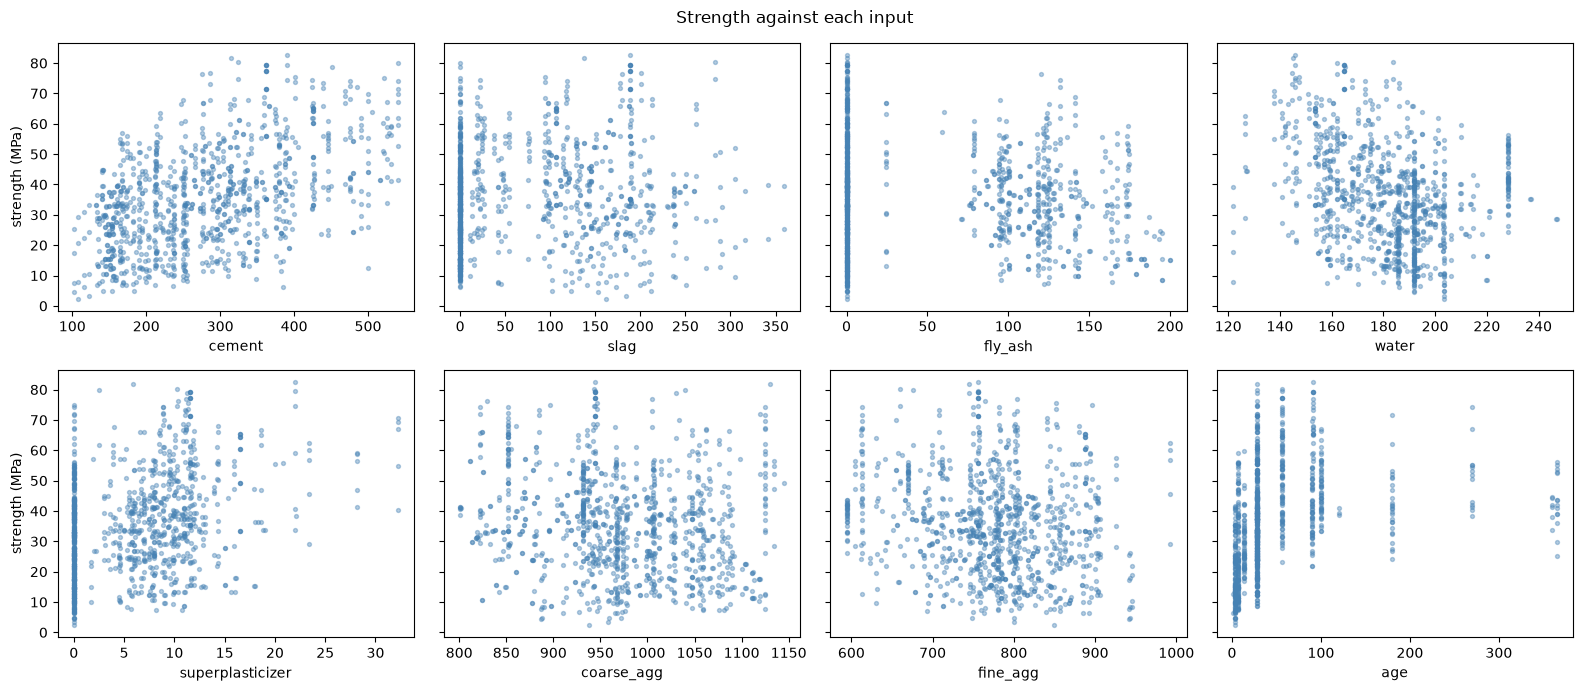

In [7]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7), sharey=True)
for ax, col in zip(axes.ravel(), features):
    ax.scatter(df[col], df["strength"], s=8, alpha=0.4, color="steelblue")
    ax.set_xlabel(col)
axes[0, 0].set_ylabel("strength (MPa)")
axes[1, 0].set_ylabel("strength (MPa)")
fig.suptitle("Strength against each input")
plt.tight_layout()
plt.show()

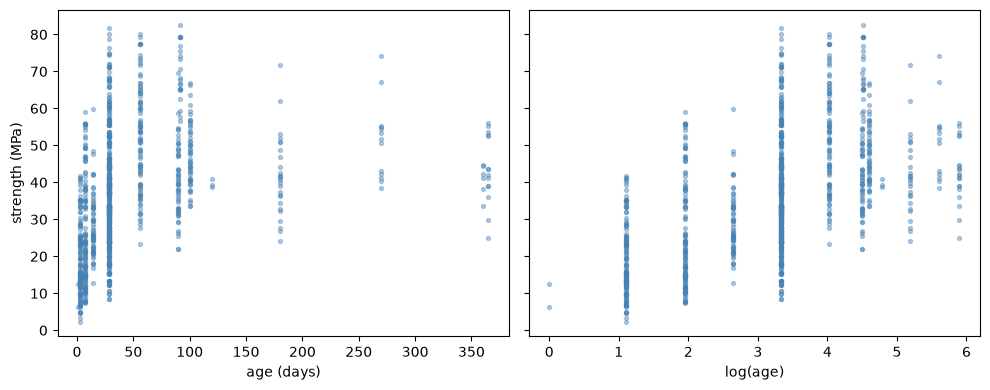

,count,mean
age,,
3,134,19.0
7,126,26.1
14,62,28.8
28,425,36.7
56,91,51.9
90,54,40.5
91,22,69.8
100,52,47.7
180,26,41.7


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
axes[0].scatter(df["age"], df["strength"], s=8, alpha=0.4, color="steelblue")
axes[0].set_xlabel("age (days)")
axes[0].set_ylabel("strength (MPa)")
axes[1].scatter(np.log(df["age"]), df["strength"], s=8, alpha=0.4, color="steelblue")
axes[1].set_xlabel("log(age)")
plt.tight_layout()
plt.show()

# mean strength at each age that has at least 20 specimens
by_age = df.groupby("age")["strength"].agg(["count", "mean"]).round(1)
by_age[by_age["count"] >= 20]

**What the descriptive analysis shows.**

The data has 1030 rows, no missing values and 25 duplicate rows (about 2.4%). We keep them, so a few validation rows have an exact copy in the training folds, which slightly flatters the scores. As expected, slag is zero in 46% of mixes, fly ash in 55% and superplasticizer in 37%. Age is the most skewed column, with a mean of 46 days and a median of 28. Strength runs from 2.3 to 82.6 MPa with a mean of 35.8.

In the scatter plots cement has the clearest positive trend and water the clearest negative one, which fits the water to cement idea in the paper. Superplasticizer is positive among the mixes that contain it, while slag, fly ash and the two aggregates show only weak trends (correlations between -0.17 and 0.13). Every plot has wide vertical scatter, so no single input explains strength. Age is the most nonlinear. Mean strength goes from 19 MPa at 3 days to 37 at 28 days and 52 at 56 days, then stays mostly between 40 and 50 at the later ages (the 22 specimens tested at 91 days, averaging 70 MPa, are the exception). The log axis makes that curve easier to see. This curved structure is what a nonlinear model should be good at.

## 3. Neural Network (40 points)

Implement a neural network as you did in the previous lab, but this time leverage the new functionalities introduced this week. Specifically:

- Your class implementing the neural network should inherit from nn.Module.

- Use `nn.Linear` for the linear transformations between layers, `nn.ReLU` for the hidden-layer activations, and the appropriate activation function for the output layer (e.g., `nn.Sigmoid` for binary classification).

- Use the appropriate cost function from `torch.nn` for your task (e.g., `nn.MSELoss`, `nn.BCELoss`).

- Use Adam from `torch.optim` as the optimizer.

- Use `DataLoader` to efficiently do batch processing. You may choose the batch size freely.

Once you have implemented this class, create an instance of it, then train and evaluate your model on the lab dataset.

**Remember to follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.**

In [10]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

X = df[features].values
y = df["strength"].values

In [11]:
class ConcreteNN(nn.Module):
    """One hidden layer ReLU network for regression. The output is a single unit with no activation."""

    def __init__(self, input_size, hidden_size):
        super().__init__()
        self.hidden = nn.Linear(input_size, hidden_size)
        self.relu = nn.ReLU()
        self.output = nn.Linear(hidden_size, 1)
        self.output_activation = nn.Identity()  # strength is unbounded, so no squashing

    def forward(self, x):
        return self.output_activation(self.output(self.relu(self.hidden(x))))

In [12]:
HIDDEN_SIZE = 8
EPOCHS = 200
LEARNING_RATE = 0.01
BATCH_SIZE = 32

def evaluate(y_true, y_pred):
    # all metrics are in the original MPa units
    return {
        "r2": r2_score(y_true, y_pred),
        "rmse": mean_squared_error(y_true, y_pred) ** 0.5,
        "mae": mean_absolute_error(y_true, y_pred),
    }

def train_nn(X_train, y_train):
    # y_train is the standardized target with shape (n, 1)
    model = ConcreteNN(X_train.shape[1], HIDDEN_SIZE)
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)
    loss_fn = nn.MSELoss()
    loader = DataLoader(TensorDataset(X_train, y_train), batch_size=BATCH_SIZE, shuffle=True)

    for epoch in range(EPOCHS):
        for X_batch, y_batch in loader:
            optimizer.zero_grad()
            loss = loss_fn(model(X_batch), y_batch)
            loss.backward()
            optimizer.step()
    return model.eval()

# the same folds are reused for every model in this lab
kf = KFold(n_splits=5, shuffle=True, random_state=42)

In [14]:
nn_rows = []
for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
    torch.manual_seed(fold)

    # fit both scalers on the training folds only to avoid leakage
    x_scaler = StandardScaler().fit(X[train_idx])
    y_scaler = StandardScaler().fit(y[train_idx].reshape(-1, 1))

    X_train = torch.tensor(x_scaler.transform(X[train_idx]), dtype=torch.float32)
    X_val = torch.tensor(x_scaler.transform(X[val_idx]), dtype=torch.float32)
    y_train = torch.tensor(y_scaler.transform(y[train_idx].reshape(-1, 1)), dtype=torch.float32)

    model = train_nn(X_train, y_train)

    # back to MPa before computing any metric
    with torch.no_grad():
        pred_train = y_scaler.inverse_transform(model(X_train).numpy())
        pred_val = y_scaler.inverse_transform(model(X_val).numpy())

    train_metrics = evaluate(y[train_idx], pred_train)
    val_metrics = evaluate(y[val_idx], pred_val)
    nn_rows.append({"fold": fold, "train_r2": train_metrics["r2"], "val_r2": val_metrics["r2"],
                    "val_rmse": val_metrics["rmse"], "val_mae": val_metrics["mae"]})

nn_results = pd.DataFrame(nn_rows).set_index("fold")
nn_results.round(3)

,train_r2,val_r2,val_rmse,val_mae
fold,,,,
1,0.883,0.858,6.055,4.782
2,0.909,0.900,5.772,4.298
3,0.895,0.861,6.281,4.656
4,0.887,0.877,5.886,4.596
5,0.872,0.827,6.397,5.061


In [15]:
summary = pd.DataFrame({"mean": nn_results.mean(), "std": nn_results.std()}).round(3)
summary

,mean,std
train_r2,0.889,0.014
val_r2,0.864,0.027
val_rmse,6.078,0.261
val_mae,4.678,0.278


**Neural network results.**

Over the five folds the network gets a validation R² of 0.864 (std 0.027), an RMSE of 6.08 MPa and an MAE of 4.68 MPa, compared with a standard deviation of 16.7 MPa in strength itself. Training R² is 0.889, a gap of only 0.025, so we see no sign of overfitting. The folds range from 0.827 (fold 5) to 0.900 (fold 2). With about 206 mixes per fold, a few badly predicted strong mixes can move one fold, which is why we average over all five. The paper reports 0.908 to 0.922 on random splits, which is higher than ours, but it used a smaller version of the data (727 mixes), its own training schedule, and we did not tune anything. The comparison with the SVM and linear regression is in Section 5.

## 4. Replication (10 points)

Replicate your neural network experiment using the corresponding model class from `scikit-learn`: https://scikit-learn.org/stable/api/sklearn.neural_network.html. Be sure to apply the same neural network architecture as well as the same procedures for model evaluation and preprocessing to ensure a fair comparison.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [16]:
import warnings
from sklearn.neural_network import MLPRegressor
from sklearn.exceptions import ConvergenceWarning

# sklearn warns when it hits max_iter, which is expected since we train for a fixed number of epochs
warnings.filterwarnings("ignore", category=ConvergenceWarning)

sk_rows = []
for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
    # same scaling procedure as the PyTorch version, fit on the training folds only
    x_scaler = StandardScaler().fit(X[train_idx])
    y_scaler = StandardScaler().fit(y[train_idx].reshape(-1, 1))

    X_train = x_scaler.transform(X[train_idx])
    X_val = x_scaler.transform(X[val_idx])
    y_train = y_scaler.transform(y[train_idx].reshape(-1, 1)).ravel()

    # same architecture and settings as ConcreteNN; alpha=0 removes the default L2 penalty
    # and n_iter_no_change=EPOCHS stops it from quitting early, so it trains for all 200 epochs
    sk_model = MLPRegressor(hidden_layer_sizes=(HIDDEN_SIZE,), activation="relu", solver="adam",
                            learning_rate_init=LEARNING_RATE, batch_size=BATCH_SIZE, max_iter=EPOCHS,
                            alpha=0, n_iter_no_change=EPOCHS, random_state=fold)
    sk_model.fit(X_train, y_train)

    pred_train = y_scaler.inverse_transform(sk_model.predict(X_train).reshape(-1, 1))
    pred_val = y_scaler.inverse_transform(sk_model.predict(X_val).reshape(-1, 1))

    train_metrics = evaluate(y[train_idx], pred_train)
    val_metrics = evaluate(y[val_idx], pred_val)
    sk_rows.append({"fold": fold, "train_r2": train_metrics["r2"], "val_r2": val_metrics["r2"],
                    "val_rmse": val_metrics["rmse"], "val_mae": val_metrics["mae"]})

sk_results = pd.DataFrame(sk_rows).set_index("fold")
sk_results.round(3)

,train_r2,val_r2,val_rmse,val_mae
fold,,,,
1,0.891,0.847,6.275,5.012
2,0.905,0.875,6.472,4.576
3,0.903,0.868,6.105,4.390
4,0.888,0.844,6.626,4.900
5,0.895,0.848,5.996,4.630


In [17]:
sk_summary = pd.DataFrame({"mean": sk_results.mean(), "std": sk_results.std()}).round(3)

# put the two implementations side by side
pd.concat({"PyTorch": summary["mean"], "scikit-learn": sk_summary["mean"]}, axis=1)

,PyTorch,scikit-learn
train_r2,0.889,0.896
val_r2,0.864,0.856
val_rmse,6.078,6.295
val_mae,4.678,4.702


**Replication results.**

We used `MLPRegressor` with the same architecture (one hidden layer of 8 ReLU units, linear output), the same Adam settings, batch size 32 and 200 epochs, and the same folds and scaling as the PyTorch version. Two defaults had to be changed to make it a fair comparison. `alpha` is an L2 penalty that is on by default and PyTorch has no equivalent in our code, so we set it to 0, and the default early stopping rule would end training before 200 epochs, so we set `n_iter_no_change` to 200.

The results are essentially the same. Validation R² is 0.856 (std 0.014) against 0.864 for PyTorch, RMSE is 6.30 MPa against 6.08 and MAE is 4.70 against 4.68. Those differences are far smaller than the fold to fold spread, so we would not call either implementation better. Both use the same model, the same loss and the same optimizer, so this is what we expected. The small differences probably come from the random weight initialisation, which each library does differently, and from the order of the shuffled batches. The per fold numbers also move around a bit, for example fold 2 is 0.900 in PyTorch and 0.875 in scikit-learn, so a single fold is not a reliable way to compare two runs.

## 5. Comparison (20 points)

Apply a Support Vector Machine (SVM) and Linear Regression model to the dataset, and compare their performance with that of your Neural Network.

Discuss any similarities or differences you observe in their results and provide possible explanations for these patterns.

Be sure to apply the k-fold cross-validation procedure to ensure a fair comparison across all models.

**Remember**: Follow the general requirements regarding model tuning, evaluation, and data preprocessing described earlier.

In [18]:
from sklearn.svm import SVR
from sklearn.linear_model import LinearRegression

def cross_validate(make_model):
    rows = []
    for fold, (train_idx, val_idx) in enumerate(kf.split(X), start=1):
        xs = StandardScaler().fit(X[train_idx])
        ys = StandardScaler().fit(y[train_idx].reshape(-1, 1))

        X_train = xs.transform(X[train_idx])
        X_val = xs.transform(X[val_idx])
        y_train = ys.transform(y[train_idx].reshape(-1, 1)).ravel()

        model = make_model().fit(X_train, y_train)
        pred_train = ys.inverse_transform(model.predict(X_train).reshape(-1, 1))
        pred_val = ys.inverse_transform(model.predict(X_val).reshape(-1, 1))

        train = evaluate(y[train_idx], pred_train)
        val = evaluate(y[val_idx], pred_val)
        rows.append({"fold": fold, "train_r2": train["r2"], "val_r2": val["r2"],
                     "val_rmse": val["rmse"], "val_mae": val["mae"]})
    return pd.DataFrame(rows).set_index("fold")

svm_results = cross_validate(lambda: SVR(kernel="rbf"))
lin_results = cross_validate(LinearRegression)

pd.concat({"SVM": svm_results, "Linear": lin_results}, axis=1).round(3)

SVM                           Linear                        
     train_r2 val_r2 val_rmse val_mae train_r2 val_r2 val_rmse val_mae
fold                                                                  
1       0.885  0.830    6.625   4.890    0.611  0.628    9.796   7.746
2       0.880  0.820    7.767   5.438    0.620  0.594   11.658   9.243
3       0.886  0.834    6.846   4.879    0.629  0.557   11.195   9.000
4       0.878  0.860    6.275   4.652    0.598  0.678    9.535   7.538
5       0.885  0.811    6.679   5.090    0.628  0.547   10.338   8.183

In [19]:
comparison = pd.DataFrame({
    "Neural network (PyTorch)": nn_results.mean(),
    "Neural network (sklearn)": sk_results.mean(),
    "SVM (RBF)": svm_results.mean(),
    "Linear regression": lin_results.mean(),
}).T

comparison["val_r2_std"] = [nn_results["val_r2"].std(), sk_results["val_r2"].std(),
                            svm_results["val_r2"].std(), lin_results["val_r2"].std()]
comparison.round(3)

,train_r2,val_r2,val_rmse,val_mae,val_r2_std
Neural network (PyTorch),0.889,0.864,6.078,4.678,0.027
Neural network (sklearn),0.896,0.856,6.295,4.702,0.014
SVM (RBF),0.883,0.831,6.839,4.990,0.019
Linear regression,0.617,0.601,10.504,8.342,0.053


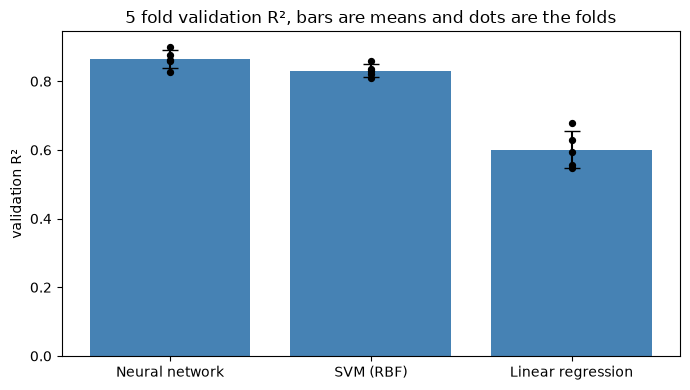

In [20]:
val_r2 = pd.DataFrame({
    "Neural network": nn_results["val_r2"],
    "SVM (RBF)": svm_results["val_r2"],
    "Linear regression": lin_results["val_r2"],
})

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(val_r2.columns, val_r2.mean(), yerr=val_r2.std(), capsize=6, color="steelblue")
for i, col in enumerate(val_r2.columns):
    ax.scatter([i] * len(val_r2), val_r2[col], color="black", s=18, zorder=3)
ax.set_ylabel("validation R²")
ax.set_title("5 fold validation R², bars are means and dots are the folds")
plt.tight_layout()
plt.show()

In [ ]:
resid = []
for train_idx, val_idx in kf.split(X):
    xs = StandardScaler().fit(X[train_idx])
    ys = StandardScaler().fit(y[train_idx].reshape(-1, 1))
    m = LinearRegression().fit(xs.transform(X[train_idx]), ys.transform(y[train_idx].reshape(-1, 1)).ravel())
    pred = ys.inverse_transform(m.predict(xs.transform(X[val_idx])).reshape(-1, 1)).ravel()
    resid.append(pd.DataFrame({"age": df["age"].values[val_idx], "residual": y[val_idx] - pred}))

resid = pd.concat(resid)
# mean residual (actual minus predicted) by age group; negative means the model predicts too high
display(resid.groupby(pd.cut(resid["age"], [0, 7, 28, 90, 400]), observed=True)["residual"].agg(["count", "mean"]).round(1))

df_log = df[features].copy()
df_log["age"] = np.log(df_log["age"])
X_log = df_log.values

scores = []
for train_idx, val_idx in kf.split(X_log):
    xs = StandardScaler().fit(X_log[train_idx])
    ys = StandardScaler().fit(y[train_idx].reshape(-1, 1))
    m = LinearRegression().fit(xs.transform(X_log[train_idx]), ys.transform(y[train_idx].reshape(-1, 1)).ravel())
    scores.append(r2_score(y[val_idx], ys.inverse_transform(m.predict(xs.transform(X_log[val_idx])).reshape(-1, 1))))

print(f"regression w log (age), val R2 = {np.mean(scores):.3f}")

print(f"linear kernel SVM, val R2 = {cross_validate(lambda: SVR(kernel='linear'))['val_r2'].mean():.3f}")
print(f"RBF SVM with C=10, val R2 = {cross_validate(lambda: SVR(kernel='rbf', C=10))['val_r2'].mean():.3f}")

linear regression with log(age), val R2 = 0.812
linear kernel SVM, val R2 = 0.569
RBF SVM with C=10, val R2 = 0.876


**Comparison.**

All four models ran on the same five folds, with both scalers fit inside each fold, and every number below is in MPa. The PyTorch network averaged a validation R² of 0.864 with a standard deviation of 0.027 across folds, an RMSE of 6.08 and an MAE of 4.68, against a training R² of 0.889. Its scikit-learn twin came out at 0.856 with a standard deviation of 0.014, an RMSE of 6.30, an MAE of 4.70 and a training R² of 0.896. The RBF SVM on library defaults reached 0.831 with a standard deviation of 0.019, an RMSE of 6.84 and an MAE of 4.99, training at 0.883. Linear regression trailed well behind at 0.601, with a standard deviation of 0.053, an RMSE of 10.50, an MAE of 8.34 and a training R² of only 0.617. Lined up like that, the table says two fairly different things at once. The first is that the two nonlinear models finish close enough that we are not going to oversell it. 0.864 for the network, 0.831 for the RBF SVM, and the folds themselves move by about 0.02, so a gap of 0.03 is a lead and not a verdict. We will admit we wanted the network to pull away. It didn't, and in hindsight that is the sensible outcome, because a one layer ReLU network and an RBF kernel are both allowed to bend wherever the data bends, and both are looking at the same eight standardized inputs, so once a model can curve at all it picks up most of what is there to pick up. The second thing is less subtle, which is where linear regression comes in. It sits a long way back at 0.601, with an RMSE of 10.50 MPa against a strength standard deviation of 16.7, and the number we actually find interesting is its training score of 0.617. There is almost no gap. The model is not failing to generalize, it never managed to describe the data in the first place, which is bias rather than variance and a cleaner kind of failure to write about. Its fold spread is also the widest of the four, 0.547 to 0.678, because how badly it misses depends on which part of the curve each fold happens to hand it, and that is the clue worth following. Section 2 had already told us this would happen, which was satisfying in a small way. Strength rises steeply through the first month of curing and then flattens out, so a straight line has to pick one slope for age and live with it everywhere. Pooled over the folds it overpredicts specimens of 7 days or less by 10.4 MPa and underpredicts the 56 to 90 day group by 8.4 MPa. Then we swapped age for log(age), changed nothing else, and validation R² went from 0.601 to 0.812. One transform. That was the point in the lab where the plots and the numbers finally agreed with each other, and the nonlinear models had been finding that curve on their own the whole time. Before we take that as a clean win, though, there are two things we would rather say than leave buried. The SVM does well because of its kernel and not because it is an SVM, since the same procedure with a linear kernel drops to 0.569, a shade under ordinary least squares. And ours is running on defaults, where C = 1 turns out to be timid for this data, with 742 of the 1030 points ending up as support vectors. Set C to 10 and it reaches 0.876, which is above our network. That one stung slightly, and we are reporting it anyway, because the alternative is quietly keeping the comparison that flatters us. The defensible claim is that our network beats a default RBF SVM, not that it beats SVMs. What the folds do settle is the ordering of the families. Both nonlinear models cut the RMSE by 35 to 42 percent against linear regression, and every one of them still sits under the 0.908 to 0.922 that Yeh reports for a tuned network on a smaller version of this data, which feels like the right note to end on.

## 6. Collaboration Reflection (5 points)

As a group, identify **one specific challenge or inefficiency** you encountered while working on this lab. In 3–5 sentences:

1. Briefly describe what happened and how it affected your work.
2. Identify one concrete action your group will take to avoid or better manage this issue in the next lab.

If your group encountered no major problem, identify one aspect of your collaboration that could still be improved.

Two of us wrote Section 5 separately on the same night, each without knowing the other had already started it. One complete version of the code and discussion was thrown away, and that time could have gone into checking the rest of the notebook before the deadline. It happened because we split the sections early on but never said who had picked up the last ones. For the next lab, we will claim each section in our group chat before starting it and post when it is pushed, so nobody starts work that is already in progress.